# 01 · Your first real embedding map

Install from the repository: `python -m pip install -e ".[demo,aef]"`.
Python 3.12+, CPU. Run all cells in order. All paths below are relative.
The small real data are bundled and SHA-256 checked by `load_demo`; corruption
raises an error. No Earth Engine login or manuscript workspace is needed.
[Full tutorial](https://github.com/GISWLH/earth-embedding/blob/main/docs/tutorials/real-demos.md).
Expected time: under one minute after installation. Download during this notebook: 0 bytes.
Source: Google / Google DeepMind AlphaEarth Foundations annual **2021**, CC-BY-4.0.
The bundled 64 x 64 sample contains real nearest-pixel vectors over Wuhan
[114.40,30.51,114.42,30.53]. It is a roughly 30 m spaced point sample of a 10 m
product, not a 30 m area average or an optical RGB image.

In [1]:
%matplotlib inline
from pathlib import Path
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
from earth_embedding.demo import load_demo, pca_colors, plot_map
out = Path("outputs")
out.mkdir(exist_ok=True)
print("CPU demo; outputs are saved in ./outputs")

CPU demo; outputs are saved in ./outputs


In [2]:
aef = load_demo("aef")
print(aef.features.shape)
print(aef.metadata["attribution"])
display(aef.samples.head())

(4096, 64)
The AlphaEarth Foundations Satellite Embedding dataset is produced by Google and Google DeepMind.


,tile_id,row,col,center_lon,center_lat,minlon,minlat,maxlon,maxlat
0,aef_r000_c000,0,0,114.400156,30.510156,114.400000,30.51,114.400312,30.510313
1,aef_r000_c001,0,1,114.400469,30.510156,114.400312,30.51,114.400625,30.510313
2,aef_r000_c002,0,2,114.400781,30.510156,114.400625,30.51,114.400937,30.510313
3,aef_r000_c003,0,3,114.401094,30.510156,114.400937,30.51,114.401250,30.510313
4,aef_r000_c004,0,4,114.401406,30.510156,114.401250,30.51,114.401562,30.510313


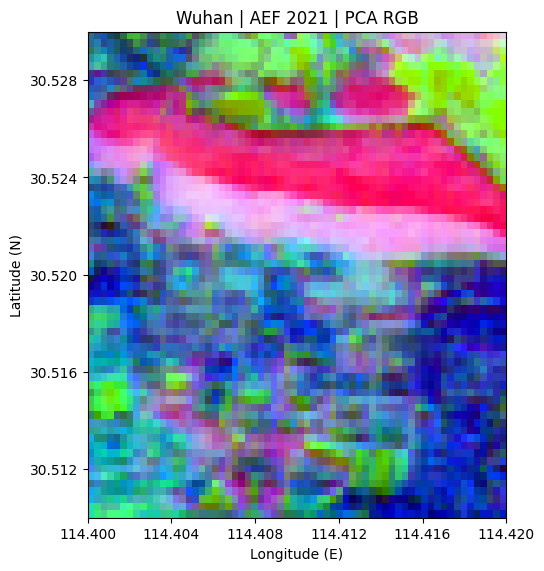

In [3]:
fig = plot_map(aef.samples, pca_colors(aef.features), title="Wuhan | AEF 2021 | PCA RGB")
fig.savefig(out / "aef-pca.png", dpi=160)
plt.show()

Red/green/blue show the first three principal components, stretched at the
2nd/98th percentiles. PCA is fitted only for this descriptive map. Colors are
**not land-cover labels** and cannot be compared to separately fitted PCA maps.
North is up; map placement uses the stored bounds, never implicit array order.

To fetch these same points yourself, install `.[aef]`, then run
`from earth_embedding.demo import fetch_aef_demo; fresh = fetch_aef_demo()`.
This reads official COG ranges (network transfer depends on COG block layout,
potentially tens of MB), checks the expected sample SHA-256, and caches the array.
Subsequent `fetch_aef_demo(offline=True)` calls use only the checked cache.
Network errors raise a clear error; the bundled `load_demo("aef")` remains usable offline.